rho = 0.0 [[1. 0.]
 [0. 1.]]
rho = 0.1 [[1.  0.1]
 [0.1 1. ]]
rho = 0.2 [[1.  0.2]
 [0.2 1. ]]
rho = 0.3 [[1.  0.3]
 [0.3 1. ]]
rho = 0.4 [[1.  0.4]
 [0.4 1. ]]
rho = 0.5 [[1.  0.5]
 [0.5 1. ]]
rho = 0.6 [[1.  0.6]
 [0.6 1. ]]
rho = 0.7 [[1.  0.7]
 [0.7 1. ]]
rho = 0.8 [[1.  0.8]
 [0.8 1. ]]
rho = 0.9 [[1.  0.9]
 [0.9 1. ]]


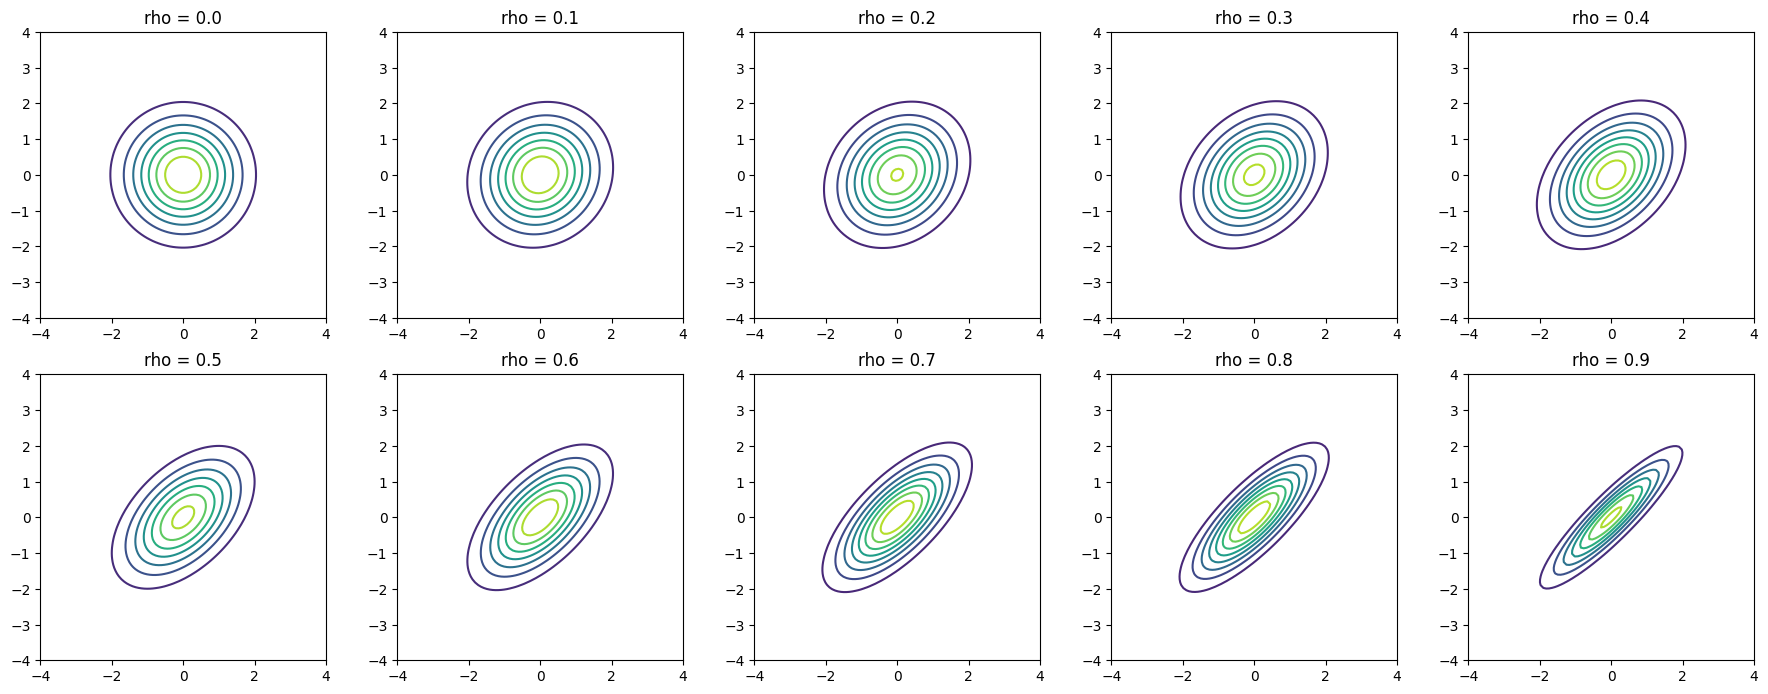

In [38]:
import numpy as np
import matplotlib.pyplot as plt

def gaussian_pdf(pts, mu, sigma):
    """pts: (M, D), mu: (D,), sigma: (D, D) -> (M,)"""
    dev = pts - mu
    inv = np.linalg.inv(sigma)
    D = len(mu)
    norm = np.sqrt((2 * np.pi) ** D * np.linalg.det(sigma))
    return np.exp(-0.5 * np.einsum('ij,jk,ik->i', dev, inv, dev)) / norm

xs = np.linspace(-4,4,100)
ys = np.linspace(-4,4,100)


#meshgrid --> n --> n x n 으로 조합해주는 것 외적같은 개념

xx, yy = np.meshgrid(xs,ys)

pts= np.c_[xx.ravel(),yy.ravel()]
#-4 ~ 4 
mu = np.array([0.0, 0.0])

sigmas = {}

for i in range(0,10):
    rho = 0.1 *i
    sigmas[f"rho = {rho:.1f}"] = np.array([
                                    [1.0, rho],
                                    [rho,1.0]])

n = len(sigmas)
fig,axes = plt.subplots(2,5,figsize=(18,7))

for ax, (name, s) in zip(axes.ravel(), sigmas.items()):
    print(name,s)
    zz = gaussian_pdf(pts, mu, s).reshape(xx.shape)
    ax.contour(xx, yy, zz, levels=8)
    ax.set_title(name)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()